In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, get_dataset, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cuda:0 NVIDIA GeForce GTX 1650 Ti


In [3]:
N_CLASSES = 52
val_loader = load_data("./dataset/playing_cards/val.pkl", 16, 0, dataset_root="./dataset/playing_cards", return_orig=True, shuffle=True)

class_index_to_string = IndexToString("./dataset/playing_cards/classes.txt")

model = PlayingCardNet(num_classes=N_CLASSES)
model.load_state_dict(torch.load("./saves/standard_playing_card_best.pth", map_location=torch.device('cpu')))
model.to(device)
model.eval()

print("model loaded")

model loaded


In [4]:
##### https://github.com/fhvilshoj/TorchLRP/blob/74253a1be05f0be0b7c535736023408670443b6e/examples/visualization.py#L60
def heatmap(X, cmap_name="seismic"):
	cmap = plt.cm.get_cmap(cmap_name)

	if X.shape[1] in [1, 3]:  # move channel index to end + convert to np array
		X = X.permute(0, 2, 3, 1).detach().cpu().numpy()
	if isinstance(X, torch.Tensor):  # convert tensor to np array
		X = X.detach().cpu().numpy()

	shape = X.shape
	tmp = X.sum(axis=-1) # Reduce channel axis

	tmp = project(tmp, output_range=(0, 255)).astype(int)
	tmp = cmap(tmp.flatten())[:, :3].T
	tmp = tmp.T

	shape = list(shape)
	shape[-1] = 3
	return tmp.reshape(shape).astype(np.float32)


def project(X, output_range=(0, 1)):
	absmax = np.abs(X).max(axis=tuple(range(1, len(X.shape))), keepdims=True)
	X /= absmax + (absmax == 0).astype(float)
	X = (X+1) / 2. # range [0, 1]
	X = output_range[0] + X * (output_range[1] - output_range[0]) # range [x, y]
	return X

In [5]:
model = convert(model).to(device)

print(model)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

## Show true classification + predicted classification

True image size (channels, width, height): torch.Size([3, 299, 299])


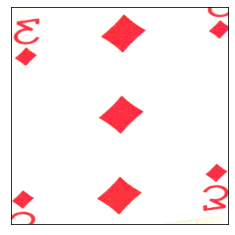

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


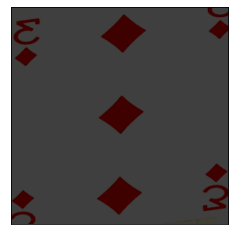

In [6]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [7]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
ouput = model(image)
_, predicted = ouput.max(1)

print("Predicted classification:", class_index_to_string(predicted.item()))

Predicted classification: 3_Diamonds


## Generate LRP saliency maps for classes using a single rule

Ace_Hearts


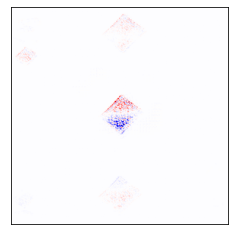

2_Hearts


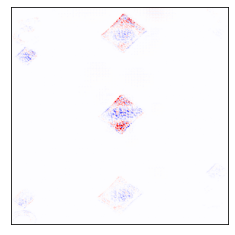

3_Hearts


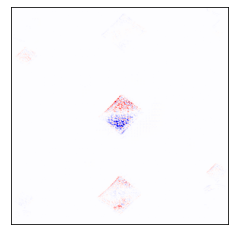

4_Hearts


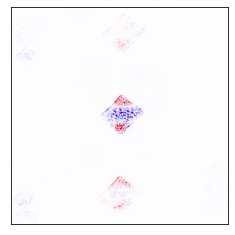

5_Hearts


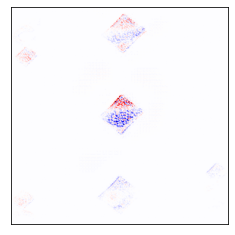

6_Hearts


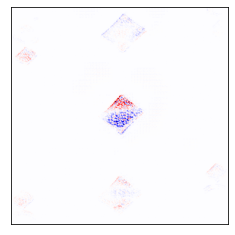

7_Hearts


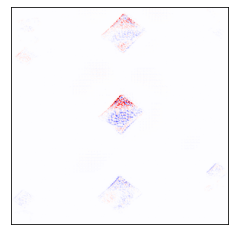

8_Hearts


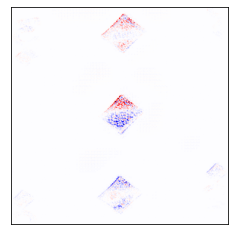

9_Hearts


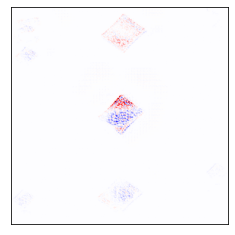

10_Hearts


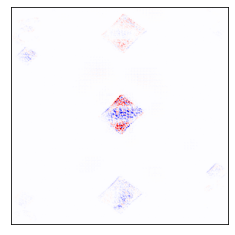

Jack_Hearts


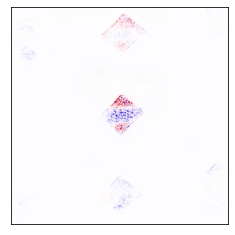

Queen_Hearts


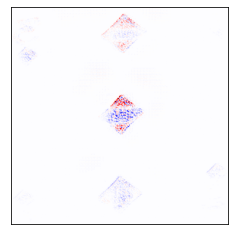

King_Hearts


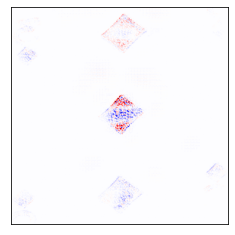

Ace_Diamonds


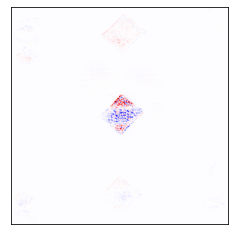

2_Diamonds


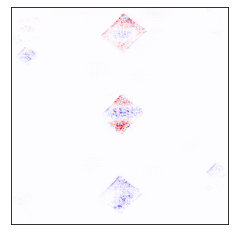

3_Diamonds


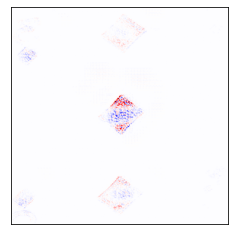

4_Diamonds


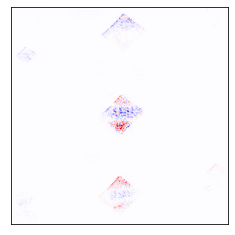

5_Diamonds


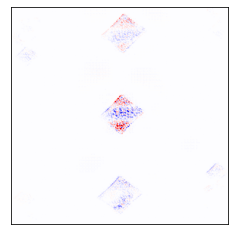

6_Diamonds


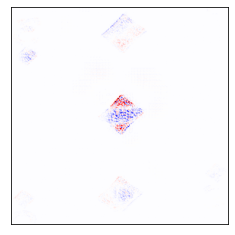

7_Diamonds


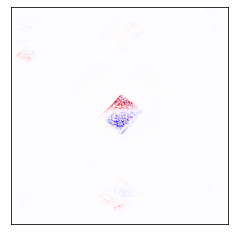

8_Diamonds


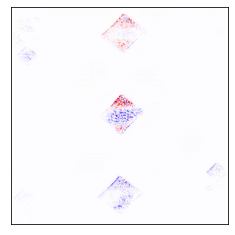

9_Diamonds


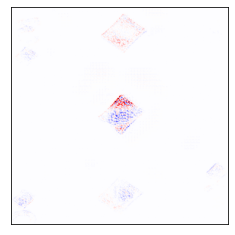

10_Diamonds


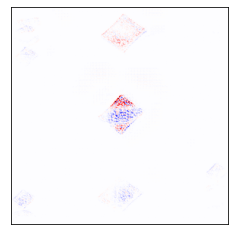

Jack_Diamonds


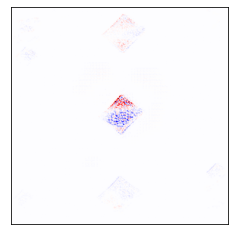

Queen_Diamonds


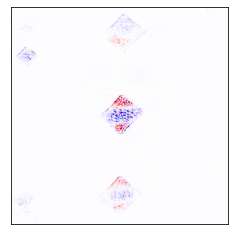

King_Diamonds


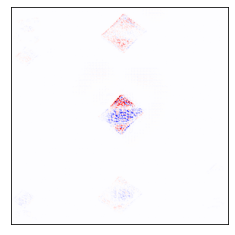

Ace_Clubs


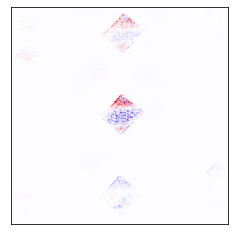

2_Clubs


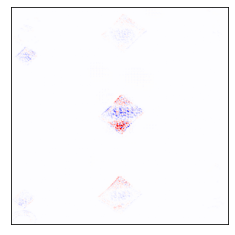

3_Clubs


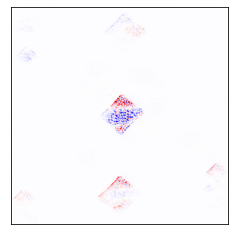

4_Clubs


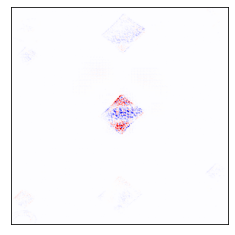

5_Clubs


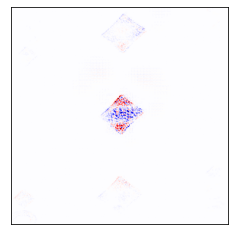

6_Clubs


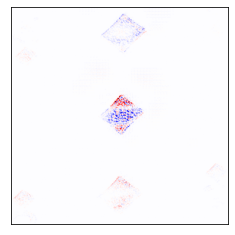

7_Clubs


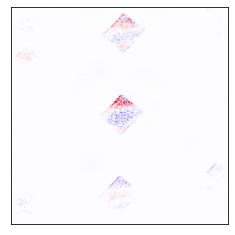

8_Clubs


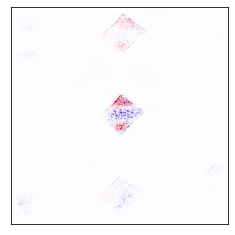

9_Clubs


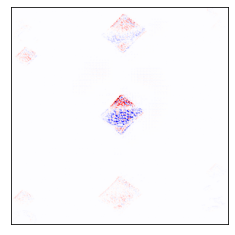

10_Clubs


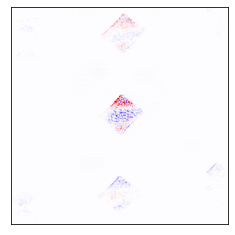

Jack_Clubs


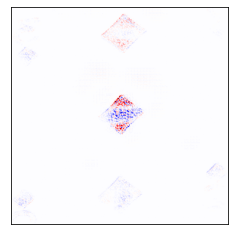

Queen_Clubs


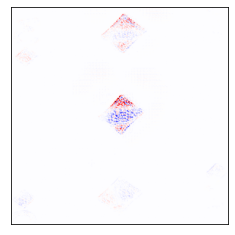

King_Clubs


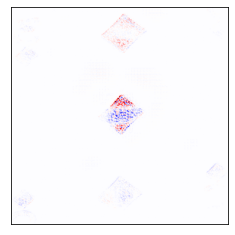

Ace_Spades


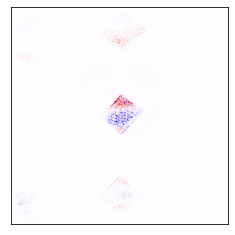

2_Spades


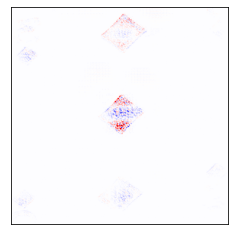

3_Spades


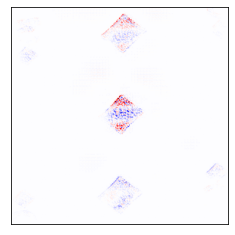

4_Spades


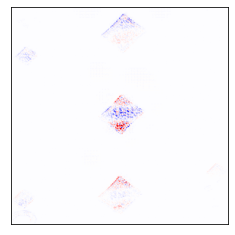

5_Spades


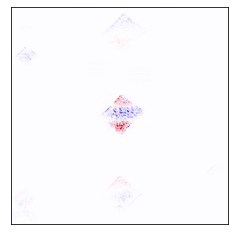

6_Spades


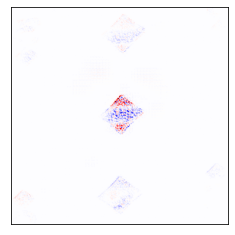

7_Spades


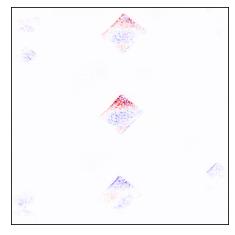

8_Spades


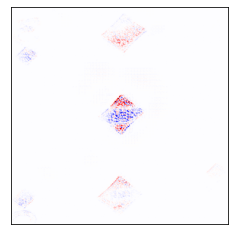

9_Spades


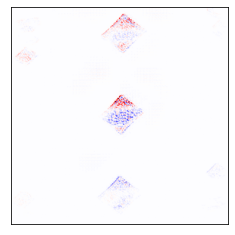

10_Spades


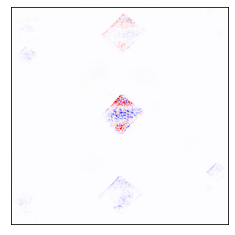

Jack_Spades


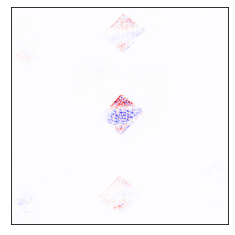

Queen_Spades


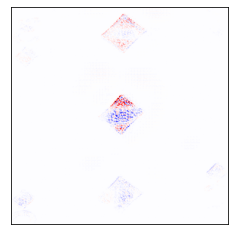

King_Spades


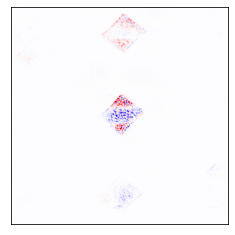

In [8]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

pred_classes = model.forward(image, explain=True, rule="alpha2beta1")
# alpha1beta0, alpha2beta1, epsilon, gradient

# get saliecy maps for each concept
for i in range(pred_classes.size(1)):
    filter_out = torch.zeros_like(pred_classes)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_classes,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(class_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    #plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close()

# composote LRP rules 

In [10]:
model_1 = []
model_2 = []
model_3 = []

for idx, m in enumerate(model.children()):
    if idx < 15:
        model_1.append(m)
    elif idx < 29:
        model_2.append(m)
    else:
        model_3.append(m)

model_1 = lrp.Sequential(*model_1)
model_2 = lrp.Sequential(*model_2)
model_3 = lrp.Sequential(*model_3)

model_1.to(device)
model_2.to(device)
model_3.to(device)

print(model_1)
print(model_2)
print(model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

Ace_Hearts


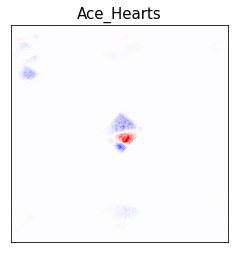

2_Hearts


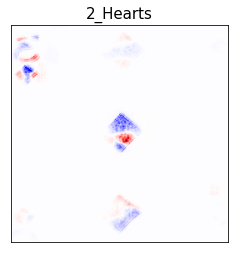

3_Hearts


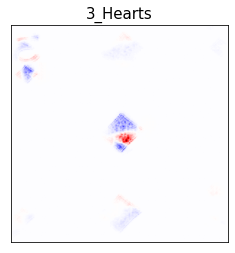

4_Hearts


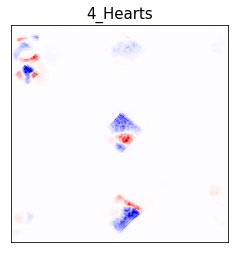

5_Hearts


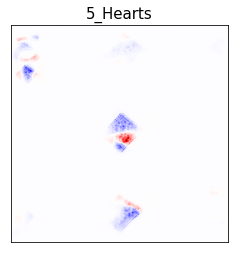

6_Hearts


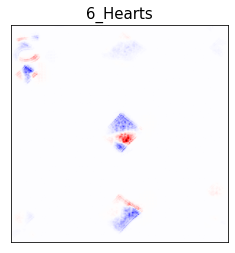

7_Hearts


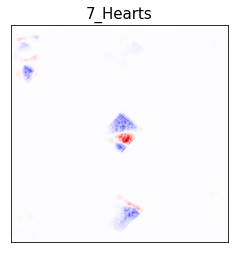

8_Hearts


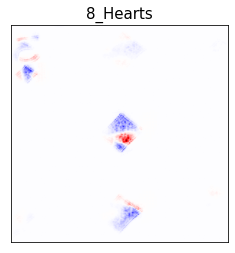

9_Hearts


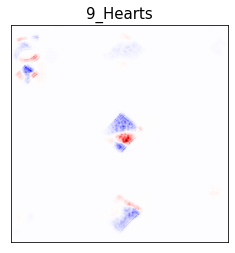

10_Hearts


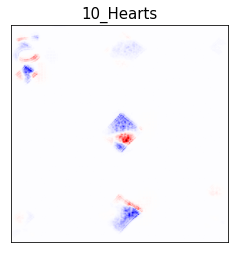

Jack_Hearts


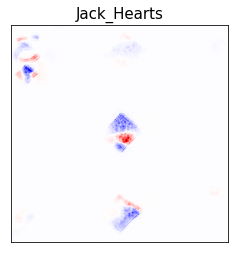

Queen_Hearts


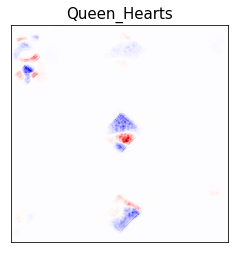

King_Hearts


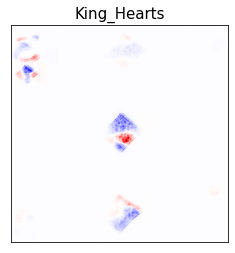

Ace_Diamonds


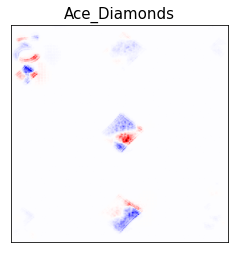

2_Diamonds


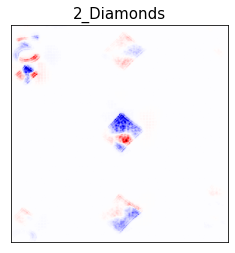

3_Diamonds


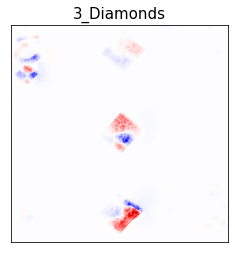

4_Diamonds


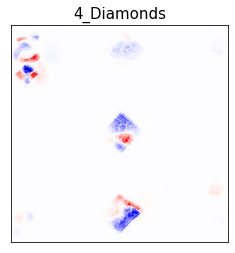

5_Diamonds


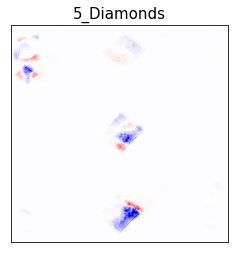

6_Diamonds


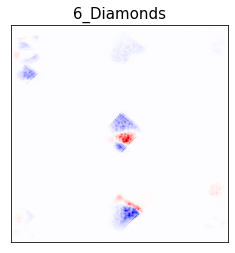

7_Diamonds


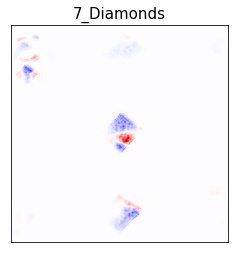

8_Diamonds


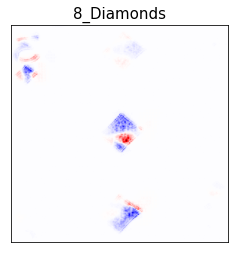

9_Diamonds


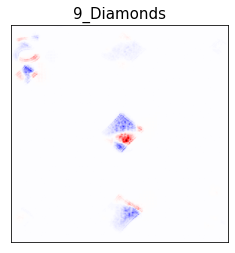

10_Diamonds


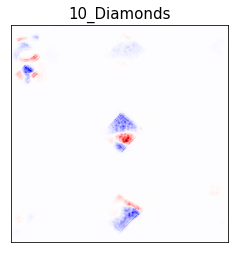

Jack_Diamonds


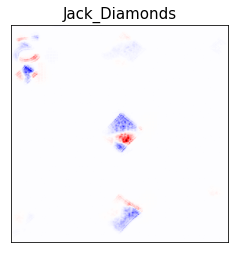

Queen_Diamonds


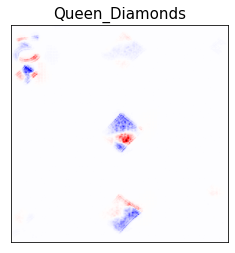

King_Diamonds


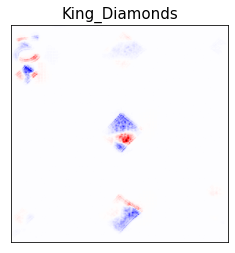

Ace_Clubs


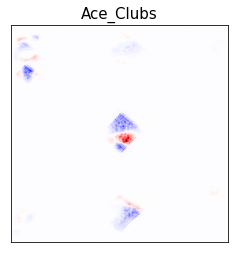

2_Clubs


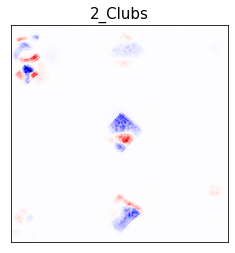

3_Clubs


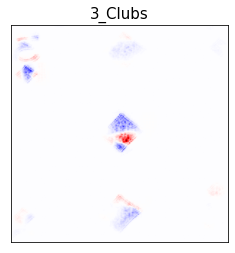

4_Clubs


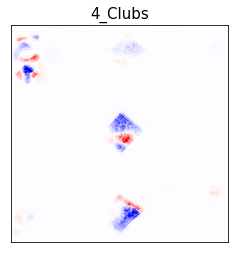

5_Clubs


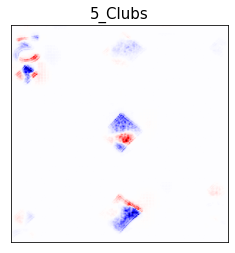

6_Clubs


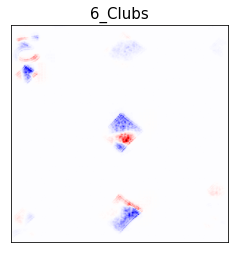

7_Clubs


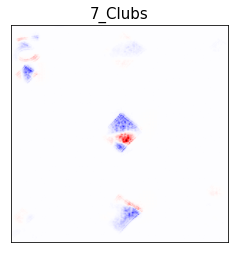

8_Clubs


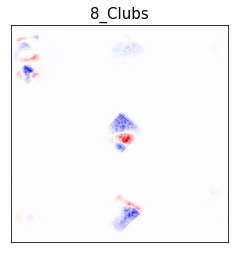

9_Clubs


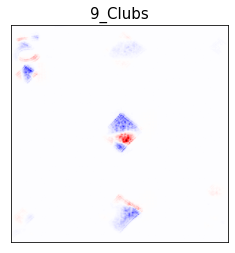

10_Clubs


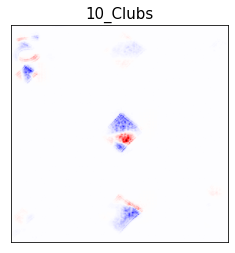

Jack_Clubs


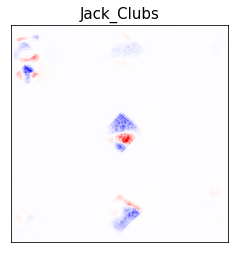

Queen_Clubs


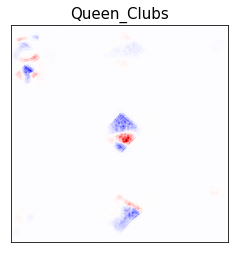

King_Clubs


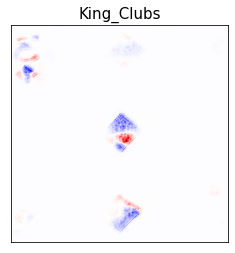

Ace_Spades


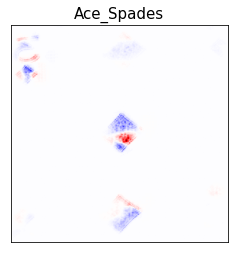

2_Spades


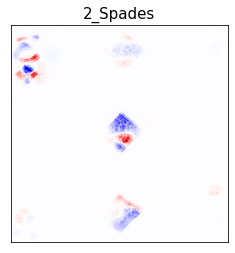

3_Spades


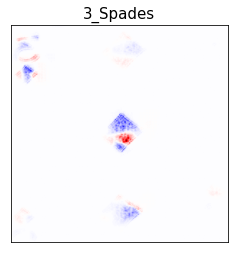

4_Spades


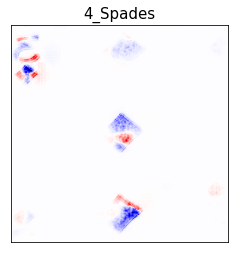

5_Spades


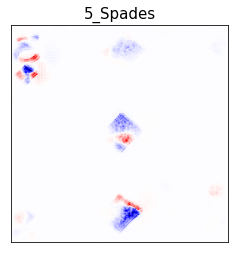

6_Spades


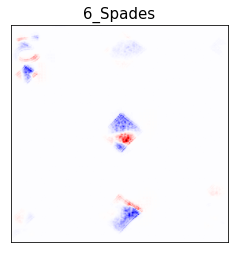

7_Spades


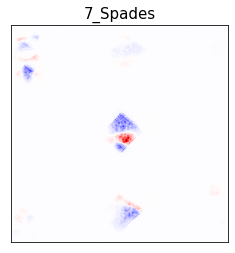

8_Spades


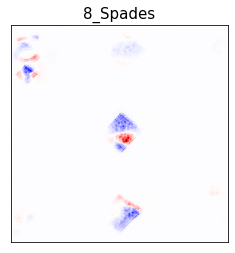

9_Spades


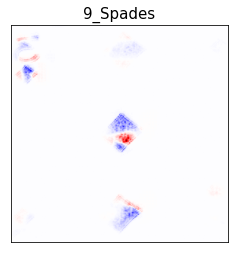

10_Spades


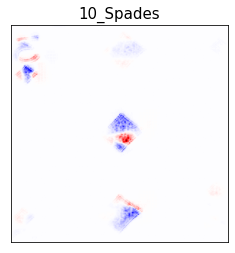

Jack_Spades


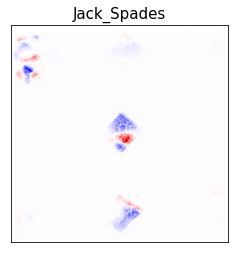

Queen_Spades


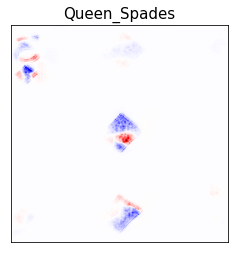

King_Spades


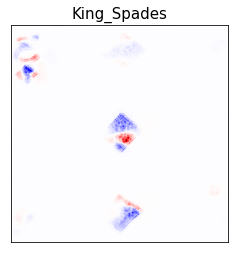

In [12]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = model_3.forward(output_2, explain=True, rule="gradient")

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(class_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    plt.title(label=class_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 